In [2]:
from google.colab import files

arquivos = files.upload()


Saving student_exam_scores.csv to student_exam_scores.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [5]:
df = pd.read_csv("student_exam_scores.csv")

print("Quantidade de estudantes:", len(df))
print(df.head())
print(df.columns)

Quantidade de estudantes: 200
  student_id  hours_studied  sleep_hours  attendance_percent  previous_scores  \
0       S001            8.0          8.8                72.1               45   
1       S002            1.3          8.6                60.7               55   
2       S003            4.0          8.2                73.7               86   
3       S004            3.5          4.8                95.1               66   
4       S005            9.1          6.4                89.8               71   

   exam_score  
0        30.2  
1        25.0  
2        35.8  
3        34.0  
4        40.3  
Index(['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores', 'exam_score'],
      dtype='object')


In [6]:
X = df[["hours_studied"]]
y = df["exam_score"]

print("Total de observações:", len(df))

Total de observações: 200


In [7]:
modelo = LinearRegression()

modelo.fit(X, y)

print("Inclinação:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)
print("R²:", modelo.score(X, y))

Inclinação: 1.6341098961284775
Intercepto: 23.618437852039314
R²: 0.6033427917418744


In [8]:
previsoes = modelo.predict(X)

resultado = df[["student_id", "hours_studied", "exam_score"]].copy()
resultado["nota_prevista"] = previsoes

print(resultado.head(10))

  student_id  hours_studied  exam_score  nota_prevista
0       S001            8.0        30.2      36.691317
1       S002            1.3        25.0      25.742781
2       S003            4.0        35.8      30.154877
3       S004            3.5        34.0      29.337822
4       S005            9.1        40.3      38.488838
5       S006            8.4        35.7      37.344961
6       S007           10.8        37.9      41.266825
7       S008            2.0        18.3      26.886658
8       S009            5.6        34.7      32.769453
9       S010            1.3        24.7      25.742781


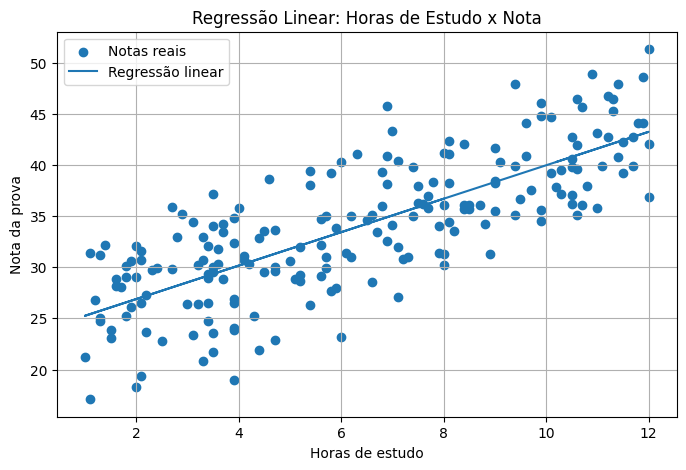

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["hours_studied"],
    df["exam_score"],
    label="Notas reais"
)

plt.plot(
    df["hours_studied"],
    previsoes,
    label="Regressão linear"
)

plt.xlabel("Horas de estudo")
plt.ylabel("Nota da prova")
plt.title("Regressão Linear: Horas de Estudo x Nota")
plt.legend()
plt.grid(True)

plt.show()

In [10]:
r2 = r2_score(y, previsoes)

print("RESULTADOS DA REGRESSÃO LINEAR")
print("------------------------------")
print(f"Estudantes analisados: {len(df)}")
print(f"Inclinação: {modelo.coef_[0]:.4f}")
print(f"Intercepto: {modelo.intercept_:.4f}")
print(f"R²: {r2:.4f}")

print(
    f"Equação: Nota = {modelo.intercept_:.4f} "
    f"+ {modelo.coef_[0]:.4f} × Horas de estudo"
)

RESULTADOS DA REGRESSÃO LINEAR
------------------------------
Estudantes analisados: 200
Inclinação: 1.6341
Intercepto: 23.6184
R²: 0.6033
Equação: Nota = 23.6184 + 1.6341 × Horas de estudo
